# 🏗️ Vértice Urbano: Painel de Vendas e Obras no Power BI

**Estudo de caso de análise de dados | Metodologia CRISP-DM**

> Os dados deste projeto são **fictícios**, gerados pelo script `generate_data.py`, e qualquer semelhança com empresas reais é coincidência.

---

## 1. Entendimento do Negócio e Contextualização

### 1.1 A empresa

A **Vértice Urbano Construtora e Incorporadora** é uma empresa familiar de porte médio com sede em Campinas (SP). Ela nasceu como construtora, fazendo obras para terceiros, e com o tempo passou a **incorporar** os próprios empreendimentos: compra o terreno, aprova o projeto, lança, vende os apartamentos na planta e constrói.

Entre 2022 e 2024 a empresa viveu sua maior fase de crescimento e lançou **8 empreendimentos residenciais** em três cidades do interior paulista (**Campinas, Sorocaba e São José dos Campos**), somando **841 unidades** em três padrões:

| Padrão | Perfil do cliente | Características |
|---|---|---|
| **Econômico** | Primeiro imóvel, renda mais apertada, financiamento | Prédios maiores, apartamentos de 1 e 2 dormitórios |
| **Médio** | Famílias em ascensão | Mistura de 2 e 3 dormitórios |
| **Alto** | Público de maior renda | Poucas unidades, apartamentos amplos |

As vendas acontecem por três canais: **imobiliárias parceiras**, **plantão de vendas** (estande no próprio empreendimento) e **digital** (site e redes sociais).

### 1.2 Como funciona o negócio de uma incorporadora

O dinheiro de uma incorporadora depende de duas frentes que andam juntas:

- **Comercial:** vender as unidades rápido e manter as vendas, porque um cliente que desiste devolve o apartamento para o estoque.
- **Obras:** construir dentro do **orçamento** e do **prazo**. Todo real a mais gasto na obra sai direto da margem, e atraso gera multa contratual e desgasta a marca.

Alguns termos do setor usados ao longo do projeto:

| Termo | Significado |
|---|---|
| **VGV (Valor Geral de Vendas)** | Quanto o empreendimento vale se todas as unidades forem vendidas. O **VGV vendido** é o valor das vendas que se mantiveram ativas |
| **VSO (Vendas Sobre Oferta)** | Porcentagem do estoque disponível que foi vendida. Mede a velocidade de vendas |
| **Distrato** | O cliente desiste da compra e o contrato é desfeito |
| **Orçado x Realizado** | Custo planejado de cada etapa da obra comparado com o custo real |
| **Avanço físico** | Porcentagem da obra já construída, comparada com o previsto no cronograma |

### 1.3 O problema

O fechamento de 2025 deixou a diretoria preocupada. Os números de venda pareciam bons, mas **o lucro não acompanhou**. Nas reuniões apareciam sempre as mesmas queixas:

- o comercial comemorava as vendas, mas parte delas virava **distrato** meses depois;
- a engenharia relatava **aumento no custo dos materiais** e algumas obras **atrasadas**;
- cada área tinha a sua própria planilha, e ninguém conseguia enxergar **a empresa inteira em um lugar só**.

A diretoria pediu ao time de dados um **painel no Power BI** que reúna comercial e obras, mostre onde estão os problemas e ajude a decidir **onde agir primeiro**.

### 1.4 Perguntas de negócio

1. Como estão as vendas (**VGV vendido** e **VSO**) por empreendimento e ao longo do tempo?
2. Qual é a **taxa de distrato** e onde ela se concentra (canal de venda, padrão, tipologia)?
3. As obras estão **dentro do orçamento**? Em quais etapas o custo estoura?
4. As obras estão **no prazo**? Atraso e estouro de custo andam juntos?
5. Quais empreendimentos **precisam de atenção da diretoria** agora?

### 1.5 Escopo e data de corte

- **Período analisado:** de março de 2022 (primeiro lançamento) até **31/12/2025** (data de corte).
- **Escopo:** comercial (vendas e distratos) e obras (custo e prazo). A parte financeira (recebimentos e inadimplência) fica de fora deste projeto.

### 1.6 Como o projeto foi construído

| Etapa | Ferramenta | O que acontece |
|---|---|---|
| Preparação dos dados | Python (pandas) | Carregamento, descrição e limpeza das bases |
| Análise exploratória | Python + SQL (SQLite) | Validação dos números e das descobertas antes do painel |
| Modelagem para o painel | Python | Exportação das bases limpas no formato de esquema estrela |
| Painel | Power BI | Relacionamentos, medidas em DAX e páginas Visão Geral, Comercial e Obras |

### 1.7 Arquivos do projeto

Todos os arquivos ficam na raiz do projeto.

| Arquivo | Descrição |
|---|---|
| `generate_data.py` | Gera as bases fictícias com semente fixa |
| `developments.csv` | Empreendimentos (cidade, padrão, unidades, datas, orçamento) |
| `units.csv` | Unidades (tipologia, área, preço de tabela) |
| `sales.csv` | Vendas (data, valor, canal, status, data do distrato) |
| `construction_costs.csv` | Custo mensal por etapa da obra (orçado x realizado) |
| `construction_progress.csv` | Avanço físico mensal (previsto x realizado) |
| `construction_analysis.ipynb` | Este notebook |
| `*_clean.csv` | Bases limpas usadas pelo Power BI |
| `construction_dashboard.pbix` | Painel no Power BI |
| `theme.json` | Tema de cores do painel no Power BI |
| `construction_dashboard.pdf` | Painel exportado em PDF, para consulta sem o Power BI |
| `dashboard_*.png` | Imagens das páginas do painel usadas no README |
| `requirements.txt` | Bibliotecas e versões para reproduzir o projeto |

## 2. Bibliotecas utilizadas

| Biblioteca | Para que serve no projeto |
|---|---|
| `pandas` | Carregar, descrever, limpar e exportar as bases |
| `sqlite3` | Banco de dados em memória para as consultas SQL da análise exploratória |
| `matplotlib` | Base dos gráficos (títulos, rótulos e tamanho) |
| `seaborn` | Gráficos da análise exploratória |

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

## 3. Carregamento dos dados

As cinco bases estão na raiz do projeto e foram geradas pelo `generate_data.py`. Elas se dividem em dois tipos:

- **Cadastros:** `developments` (empreendimentos) e `units` (unidades).
- **Movimentos:** `sales` (vendas), `construction_costs` (custos mensais da obra) e `construction_progress` (avanço físico mensal).

In [2]:
developments = pd.read_csv('developments.csv')
units = pd.read_csv('units.csv')
sales = pd.read_csv('sales.csv')
construction_costs = pd.read_csv('construction_costs.csv')
construction_progress = pd.read_csv('construction_progress.csv')

tables = {
    'developments': developments,
    'units': units,
    'construction_costs': construction_costs,
    'construction_progress': construction_progress,
    'sales':sales,
}

for name, df in tables.items():
    print(f'{name}: {df.shape[0]} linhas e {df.shape[1]} colunas')

developments: 8 linhas e 8 colunas
units: 841 linhas e 5 colunas
construction_costs: 390 linhas e 5 colunas
construction_progress: 207 linhas e 4 colunas
sales: 784 linhas e 7 colunas


In [3]:
for name, df in tables.items():
    print(name)
    display(df.head(3))
    print('\n')

developments


,development_id,development_name,city,standard,launch_date,total_units,expected_delivery,budget
0,D01,Residencial Jardim das Flores,Campinas,Econômico,2022-03-01,180,2025-03-01,24112000.0
1,D02,Edifício Mirante,campinas,Alto,2022-08-01,43,2025-08-01,23352000.0
2,D03,Residencial Parque Verde,Sorocaba,Econômico,2023-01-01,141,2026-01-01,18893000.0




units


,unit_id,development_id,typology,area_m2,list_price
0,D01-001,D01,1 dormitório,39.7,231400.0
1,D01-002,D01,2 dormitórios,46.3,247900.0
2,D01-003,D01,1 dormitório,39.4,225400.0




construction_costs


,development_id,month,stage,budgeted_cost,actual_cost
0,D01,2022-06-01,Fundação,413348.57,456372.76
1,D01,2022-07-01,Fundação,413348.57,455887.20
2,D01,2022-08-01,Fundação,413348.57,426752.13




construction_progress


,development_id,month,planned_progress,actual_progress
0,D01,2022-06-01,0.3,0.3
1,D01,2022-07-01,1.0,1.0
2,D01,2022-08-01,2.2,2.2




sales


,sale_id,unit_id,sale_date,sale_value,channel,status,cancel_date
0,V00001,D01-001,2022-09-08,226200.0,Digital,Ativa,NaN
1,V00002,D01-002,2022-06-07,247700.0,Digital,Ativa,NaN
2,V00003,D01-003,2025-12-14,210500.0,Plantão de vendas,Ativa,NaN


## 4. Descrição dos dados

Antes de limpar, vamos entender o estado das bases: tipos das colunas, duplicados, nulos e inconsistências. Ao final, uma tabela resume os problemas encontrados e o que será feito com cada um.

### 4.1 Tipos das colunas

In [4]:
for name, df in tables.items():
    print(name)
    print(df.dtypes, '\n')

developments
development_id           str
development_name         str
city                     str
standard                 str
launch_date              str
total_units            int64
expected_delivery        str
budget               float64
dtype: object 

units
unit_id               str
development_id        str
typology              str
area_m2           float64
list_price        float64
dtype: object 

construction_costs
development_id        str
month                 str
stage                 str
budgeted_cost     float64
actual_cost       float64
dtype: object 

construction_progress
development_id          str
month                   str
planned_progress    float64
actual_progress     float64
dtype: object 

sales
sale_id            str
unit_id            str
sale_date          str
sale_value     float64
channel            str
status             str
cancel_date        str
dtype: object 



### 4.2 Duplicados e nulos

In [5]:
summary = pd.DataFrame({
    'linhas': [len(df) for df in tables.values()],
    'duplicados': [df.duplicated().sum() for df in tables.values()],
}, index=tables.keys())

summary

,linhas,duplicados
developments,8,0
units,841,0
construction_costs,390,10
construction_progress,207,0
sales,784,22


In [6]:
for name, df in tables.items():
    nulls = df.isna().sum()
    print(name, nulls[nulls > 0].to_dict())

developments {}
units {}
construction_costs {'actual_cost': 5}
construction_progress {}
sales {'sale_value': 6, 'channel': 19, 'cancel_date': 683}


**Observações:**

- **Datas como texto:** todas as colunas de data (`launch_date`, `expected_delivery`, `sale_date`, `cancel_date` e `month`) vieram como texto. Elas precisam virar data para permitir cálculos de prazo e a criação da linha do tempo no Power BI.
- **Cadastros sem problemas de nulos ou duplicados:** `developments`, `units` e `construction_progress` estão completas.
- **`sales`:** 22 linhas duplicadas, 6 vendas sem valor (`sale_value`) e 19 sem canal (`channel`).
- **`cancel_date` com 683 nulos:** não é erro. Venda ativa não tem data de distrato, e o número bate com a quantidade de vendas com status "Ativa" (conferido na seção 4.4).
- **`construction_costs`:** 10 linhas duplicadas e 5 meses sem custo realizado (`actual_cost`).

### 4.3 Textos escritos de formas diferentes

In [7]:
print(developments['city'].value_counts(), '\n')
print(sales['channel'].value_counts(dropna=False))

city
Campinas               2
Sorocaba               2
campinas               1
Sao Jose dos Campos    1
SOROCABA               1
São José dos Campos    1
Name: count, dtype: int64 

channel
Imobiliária parceira    331
Plantão de vendas       196
Digital                 174
imobiliaria parceira     25
NaN                      19
Imobiliária              12
Plantão                  11
plantao de vendas         8
digital                   4
Online                    3
DIGITAL                   1
Name: count, dtype: int64


### 4.4 Datas e valores impossíveis

In [8]:
checks = {
    'distrato antes da venda': (sales['cancel_date'] < sales['sale_date']).sum(),
    'venda ativa com data de distrato': ((sales['status'] == 'Ativa') & sales['cancel_date'].notna()).sum(),
    'venda distratada sem data de distrato': ((sales['status'] == 'Distratada') & sales['cancel_date'].isna()).sum(),
    'custo realizado negativo': (construction_costs['actual_cost'] < 0).sum(),
}

for check, total in checks.items():
    print(f'{check}: {total}')

print('\nStatus das vendas:')
print(sales['status'].value_counts())

distrato antes da venda: 6
venda ativa com data de distrato: 0
venda distratada sem data de distrato: 0
custo realizado negativo: 4

Status das vendas:
status
Ativa         683
Distratada    101
Name: count, dtype: int64


**Observações:**

- **Cidades:** 3 cidades escritas de 6 formas diferentes (maiúsculas, falta de acento e espaço no final). Sem padronização, o Power BI mostraria a mesma cidade em barras separadas.
- **Canais de venda:** 3 canais escritos de 10 formas diferentes, além de 19 vendas sem canal.
- **Distrato antes da venda:** 6 vendas têm a data do distrato anterior à data da venda, o que é impossível. Uma delas é linha duplicada.
- **Consistência do status:** nenhuma venda ativa tem data de distrato e nenhuma venda distratada está sem data. Os 683 nulos de `cancel_date` são exatamente as 683 vendas ativas.
- **Custo negativo:** 4 meses com custo realizado negativo. Os valores têm o tamanho esperado, só com o sinal trocado, o que indica erro de digitação.

### 4.5 Resumo dos problemas e decisões

| Base | Problema | Quantidade | Decisão |
|---|---|---|---|
| Todas | Datas armazenadas como texto | 5 colunas | Converter para data |
| `developments` | Cidades escritas de formas diferentes | 3 registros | Padronizar para Campinas, Sorocaba e São José dos Campos |
| `sales` | Linhas duplicadas | 22 | Remover |
| `sales` | Canais escritos de formas diferentes | 64 | Padronizar para Imobiliária parceira, Plantão de vendas e Digital |
| `sales` | Venda sem canal | 19 | Preencher com "Não informado", para a venda continuar contando no VGV |
| `sales` | Venda sem valor | 6 | Preencher com o preço de tabela da unidade (estimativa, sem o desconto) |
| `sales` | Distrato com data anterior à venda | 5 (após remover duplicados) | Manter como distrato e deixar a data vazia, porque a data correta não é conhecida |
| `sales` | `cancel_date` vazio em vendas ativas | 683 | Manter, pois é o comportamento esperado |
| `construction_costs` | Linhas duplicadas | 10 | Remover |
| `construction_costs` | Custo realizado negativo | 4 | Inverter o sinal (erro de digitação) |
| `construction_costs` | Custo realizado vazio | 5 | Remover a linha, porque sem o realizado não dá para comparar com o orçado |

## 5. Limpeza

A limpeza segue as decisões da seção 4.5. Os duplicados são removidos primeiro, para que as correções seguintes sejam aplicadas sobre as linhas únicas.

### 5.1 Duplicados

In [9]:
sales = sales.drop_duplicates().reset_index(drop=True)
construction_costs = construction_costs.drop_duplicates().reset_index(drop=True)

print(f'sales: {len(sales)} linhas')
print(f'construction_costs: {len(construction_costs)} linhas')

sales: 762 linhas
construction_costs: 380 linhas


### 5.2 Datas

In [10]:
developments['launch_date'] = pd.to_datetime(developments['launch_date'])
developments['expected_delivery'] = pd.to_datetime(developments['expected_delivery'])
sales['sale_date'] = pd.to_datetime(sales['sale_date'])
sales['cancel_date'] = pd.to_datetime(sales['cancel_date'])
construction_costs['month'] = pd.to_datetime(construction_costs['month'])
construction_progress['month'] = pd.to_datetime(construction_progress['month'])

sales.dtypes

sale_id                   str
unit_id                   str
sale_date      datetime64[us]
sale_value            float64
channel                   str
status                    str
cancel_date    datetime64[us]
dtype: object

### 5.3 Cidades e canais de venda

In [11]:
city_map = {
    'campinas': 'Campinas',
    'SOROCABA': 'Sorocaba',
    'Sao Jose dos Campos': 'São José dos Campos',
}

channel_map = {
    'imobiliaria parceira': 'Imobiliária parceira',
    'Imobiliária': 'Imobiliária parceira',
    'plantao de vendas': 'Plantão de vendas',
    'Plantão': 'Plantão de vendas',
    'digital': 'Digital',
    'DIGITAL': 'Digital',
    'Online': 'Digital',
}

developments['city'] = developments['city'].str.strip().replace(city_map)
sales['channel'] = sales['channel'].replace(channel_map).fillna('Não informado')

print(developments['city'].value_counts(), '\n')
print(sales['channel'].value_counts())

city
Campinas               3
Sorocaba               3
São José dos Campos    2
Name: count, dtype: int64 

channel
Imobiliária parceira    358
Plantão de vendas       210
Digital                 176
Não informado            18
Name: count, dtype: int64


### 5.4 Valores vazios e impossíveis

In [12]:
list_prices = sales['unit_id'].map(units.set_index('unit_id')['list_price'])
sales['sale_value'] = sales['sale_value'].fillna(list_prices)

sales.loc[sales['cancel_date'] < sales['sale_date'], 'cancel_date'] = pd.NaT

construction_costs['actual_cost'] = construction_costs['actual_cost'].abs()
construction_costs = construction_costs.dropna(subset=['actual_cost']).reset_index(drop=True)

### 5.5 Conferência final

In [13]:
tables = {
    'developments': developments,
    'units': units,
    'sales': sales,
    'construction_costs': construction_costs,
    'construction_progress': construction_progress,
}

for name, df in tables.items():
    nulls = df.isna().sum()
    print(f'{name}: {len(df)} linhas | {df.duplicated().sum()} duplicados | nulos: {nulls[nulls > 0].to_dict()}')

checks = {
    'distrato antes da venda': (sales['cancel_date'] < sales['sale_date']).sum(),
    'venda ativa com data de distrato': ((sales['status'] == 'Ativa') & sales['cancel_date'].notna()).sum(),
    'venda distratada sem data de distrato': ((sales['status'] == 'Distratada') & sales['cancel_date'].isna()).sum(),
    'custo realizado negativo': (construction_costs['actual_cost'] < 0).sum(),
}

print()
for check, total in checks.items():
    print(f'{check}: {total}')

print()
print(sales['status'].value_counts())

developments: 8 linhas | 0 duplicados | nulos: {}
units: 841 linhas | 0 duplicados | nulos: {}
sales: 762 linhas | 0 duplicados | nulos: {'cancel_date': 670}
construction_costs: 375 linhas | 0 duplicados | nulos: {}
construction_progress: 207 linhas | 0 duplicados | nulos: {}

distrato antes da venda: 0
venda ativa com data de distrato: 0
venda distratada sem data de distrato: 5
custo realizado negativo: 0

status
Ativa         665
Distratada     97
Name: count, dtype: int64


**Resumo da limpeza:**

| Base | Antes | Depois | O que mudou |
|---|---|---|---|
| `developments` | 8 | 8 | Datas convertidas e cidades padronizadas |
| `units` | 841 | 841 | Sem alterações |
| `sales` | 784 | 762 | 22 duplicados removidos, canais padronizados, 18 canais vazios como "Não informado", 6 valores preenchidos com o preço de tabela e 5 datas de distrato impossíveis apagadas |
| `construction_costs` | 390 | 375 | 10 duplicados e 5 meses sem custo realizado removidos, 4 sinais corrigidos |
| `construction_progress` | 207 | 207 | Datas convertidas |

Os únicos nulos que restaram são os 670 de `cancel_date`: 665 vendas ativas, que não têm distrato, e 5 distratos com data desconhecida.

## 6. Análise Exploratória

Cada pergunta de negócio é respondida com uma consulta SQL e um gráfico. Os números calculados aqui servem também para **validar o painel no Power BI**: as medidas em DAX precisam chegar aos mesmos resultados.

As bases limpas são carregadas em um banco SQLite em memória.

In [14]:
conn = sqlite3.connect(':memory:')

for name, df in tables.items():
    df.to_sql(name, conn, index=False)

### 6.1 Como estão as vendas por empreendimento?

- **VSO acumulado:** unidades vendidas (vendas ativas) ÷ total de unidades do empreendimento.
- **VGV total:** soma do preço de tabela de todas as unidades.
- **VGV vendido:** soma do valor das vendas ativas.

Unidades distratadas voltam para o estoque, por isso só as vendas ativas entram na conta.

In [15]:
query = '''
WITH unit_totals AS (
    SELECT development_id,
           SUM(list_price) AS total_vgv
    FROM units
    GROUP BY development_id
),
active_sales AS (
    SELECT u.development_id,
           COUNT(*) AS units_sold,
           SUM(s.sale_value) AS sold_vgv
    FROM sales s
    JOIN units u ON s.unit_id = u.unit_id
    WHERE s.status = 'Ativa'
    GROUP BY u.development_id
)
SELECT d.development_id,
       d.development_name,
       d.standard,
       ROUND((julianday('2025-12-31') - julianday(d.launch_date)) / 30.4) AS months_on_sale,
       d.total_units,
       COALESCE(a.units_sold, 0) AS units_sold,
       ROUND(100.0 * COALESCE(a.units_sold, 0) / d.total_units, 1) AS vso_pct,
       ROUND(t.total_vgv / 1000000, 1) AS total_vgv_mi,
       ROUND(COALESCE(a.sold_vgv, 0) / 1000000, 1) AS sold_vgv_mi
FROM developments d
JOIN unit_totals t ON d.development_id = t.development_id
LEFT JOIN active_sales a ON d.development_id = a.development_id
ORDER BY d.development_id
'''

sales_by_development = pd.read_sql(query, conn)
sales_by_development

,development_id,development_name,standard,months_on_sale,total_units,units_sold,vso_pct,total_vgv_mi,sold_vgv_mi
0,D01,Residencial Jardim das Flores,Econômico,46.0,180,140,77.8,45.2,34.1
1,D02,Edifício Mirante,Alto,41.0,43,36,83.7,54.8,44.3
2,D03,Residencial Parque Verde,Econômico,36.0,141,116,82.3,35.4,28.2
3,D04,Edifício Solar do Vale,Médio,32.0,97,88,90.7,52.5,45.4
4,D05,Residencial Bela Vista,Médio,28.0,95,82,86.3,50.4,41.4
5,D06,Edifício Horizonte,Econômico,24.0,154,112,72.7,38.5,27.1
6,D07,Residencial Recanto,Médio,21.0,88,65,73.9,46.5,32.2
7,D08,Edifício Alto da Serra,Alto,16.0,43,26,60.5,56.2,33.0


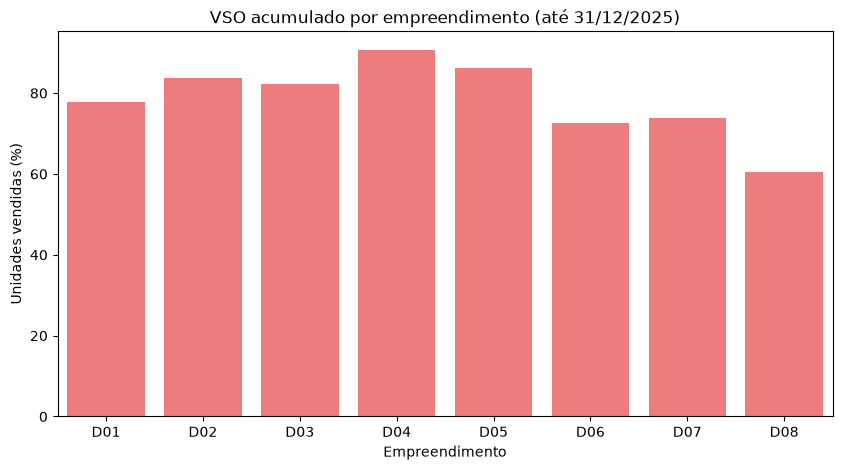

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_development, x='development_id', y='vso_pct', color='#FF6B6B')
plt.title('VSO acumulado por empreendimento (até 31/12/2025)')
plt.xlabel('Empreendimento')
plt.ylabel('Unidades vendidas (%)')
plt.show()

**Observações:**

**Fatos**
- Até 31/12/2025, a empresa vendeu **665 das 841 unidades (79,1%)**, somando **R$ 285,7 mi de VGV vendido** de um VGV total de R$ 379,5 mi (75,3%).
- O **D04 (Médio)** tem o maior VSO: **90,7%** em 32 meses à venda.
- O **D01 (Econômico)** é o empreendimento mais antigo, com 46 meses à venda, mas tem VSO de **77,8%**, abaixo de prédios mais novos como D03, D04 e D05.
- O **D06 (Econômico)** tem VSO de **72,7%** em 24 meses, abaixo do D05, que tem idade parecida.
- O **D08 (Alto)** tem o menor VSO (**60,5%**), mas é o lançamento mais recente, com 16 meses.

**Hipóteses**
- Os empreendimentos econômicos (D01 e D06) podem estar vendendo bem, mas perdendo vendas para distratos, já que unidade distratada volta para o estoque. Isso é investigado na seção 6.3.
- O VSO do D08 é compatível com a idade do empreendimento e, por enquanto, não indica problema.

**Recomendação**
- Comparar o VSO sempre junto com o tempo de venda do empreendimento. No painel, os dois indicadores devem aparecer lado a lado.

### 6.2 Como as vendas evoluíram ao longo do tempo?

As vendas são agrupadas pelo **ano em que aconteceram**, separando as que continuam ativas das que viraram distrato depois.

In [18]:
query = '''
SELECT strftime('%Y', sale_date) AS sale_year,
       COUNT(*) AS total_sales,
       SUM(CASE WHEN status = 'Ativa' THEN 1 ELSE 0 END) AS active_sales,
       SUM(CASE WHEN status = 'Distratada' THEN 1 ELSE 0 END) AS cancelled_sales,
       ROUND(100.0 * SUM(CASE WHEN status = 'Distratada' THEN 1 ELSE 0 END) / COUNT(*), 1) AS cancel_rate_pct,
       ROUND(SUM(CASE WHEN status = 'Ativa' THEN sale_value ELSE 0 END) / 1000000, 1) AS sold_vgv_mi
FROM sales
GROUP BY sale_year
ORDER BY sale_year
'''

sales_by_year = pd.read_sql(query, conn)
sales_by_year

,sale_year,total_sales,active_sales,cancelled_sales,cancel_rate_pct,sold_vgv_mi
0,2022,87,69,18,20.7,28.5
1,2023,240,207,33,13.8,86.2
2,2024,313,274,39,12.5,116.6
3,2025,122,115,7,5.7,54.4


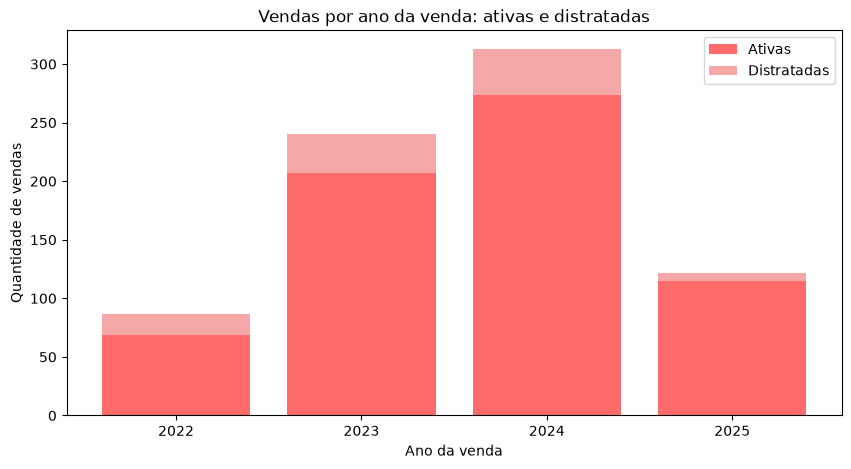

In [19]:
plt.figure(figsize=(10, 5))
plt.bar(sales_by_year['sale_year'], sales_by_year['active_sales'], color='#FF6B6B', label='Ativas')
plt.bar(sales_by_year['sale_year'], sales_by_year['cancelled_sales'],
        bottom=sales_by_year['active_sales'], color='#f4a9a8', label='Distratadas')
plt.title('Vendas por ano da venda: ativas e distratadas')
plt.xlabel('Ano da venda')
plt.ylabel('Quantidade de vendas')
plt.legend()
plt.show()

**Observações:**

**Fatos**
- As vendas cresceram de **87 (2022)** para **313 (2024)**, o ano de pico, com **R$ 116,6 mi** de VGV vendido. Em 2025, caíram para **122**.
- A empresa não teve lançamentos em 2025. O último foi o D08, em setembro de 2024.
- As vendas de 2022 têm a maior taxa de distrato (**20,7%**). Naquele ano só estavam à venda o D01 (Econômico) e o D02 (Alto).
- As vendas de 2025 têm a menor taxa (**5,7%**).

**Hipóteses**
- A queda de 2025 está ligada à falta de lançamentos novos e ao estoque menor nos empreendimentos antigos, e não necessariamente a uma piora comercial.
- A taxa baixa de 2025 é, em boa parte, efeito do tempo: os distratos acontecem meses depois da venda, e as vendas recentes ainda não tiveram tempo de distratar. Ela **não indica** melhora.

**Recomendação**
- No painel, comparar taxas de distrato entre anos com cuidado, sempre indicando que o ano mais recente ainda está "em maturação".

### 6.3 Qual é a taxa de distrato e onde ela se concentra?

**Taxa de distrato:** vendas distratadas ÷ total de vendas. A análise compara a taxa por canal de venda, padrão do empreendimento e tipologia.

In [20]:
query = '''
WITH sales_details AS (
    SELECT s.status,
           s.channel,
           d.standard,
           u.typology
    FROM sales s
    JOIN units u ON s.unit_id = u.unit_id
    JOIN developments d ON u.development_id = d.development_id
)
SELECT 'Canal' AS dimension,
       channel AS category,
       COUNT(*) AS total_sales,
       SUM(CASE WHEN status = 'Distratada' THEN 1 ELSE 0 END) AS cancelled_sales
FROM sales_details
GROUP BY channel

UNION ALL

SELECT 'Padrão', standard, COUNT(*),
       SUM(CASE WHEN status = 'Distratada' THEN 1 ELSE 0 END)
FROM sales_details
GROUP BY standard

UNION ALL

SELECT 'Tipologia', typology, COUNT(*),
       SUM(CASE WHEN status = 'Distratada' THEN 1 ELSE 0 END)
FROM sales_details
GROUP BY typology
'''

cancellations = pd.read_sql(query, conn)
cancellations['cancel_rate_pct'] = (100 * cancellations['cancelled_sales'] / cancellations['total_sales']).round(1)
cancellations

,dimension,category,total_sales,cancelled_sales,cancel_rate_pct
0,Canal,Digital,176,42,23.9
1,Canal,Imobiliária parceira,358,29,8.1
2,Canal,Não informado,18,3,16.7
3,Canal,Plantão de vendas,210,23,11.0
4,Padrão,Alto,67,5,7.5
5,Padrão,Econômico,440,72,16.4
6,Padrão,Médio,255,20,7.8
7,Tipologia,1 dormitório,218,36,16.5
8,Tipologia,2 dormitórios,409,47,11.5
9,Tipologia,3 dormitórios,135,14,10.4


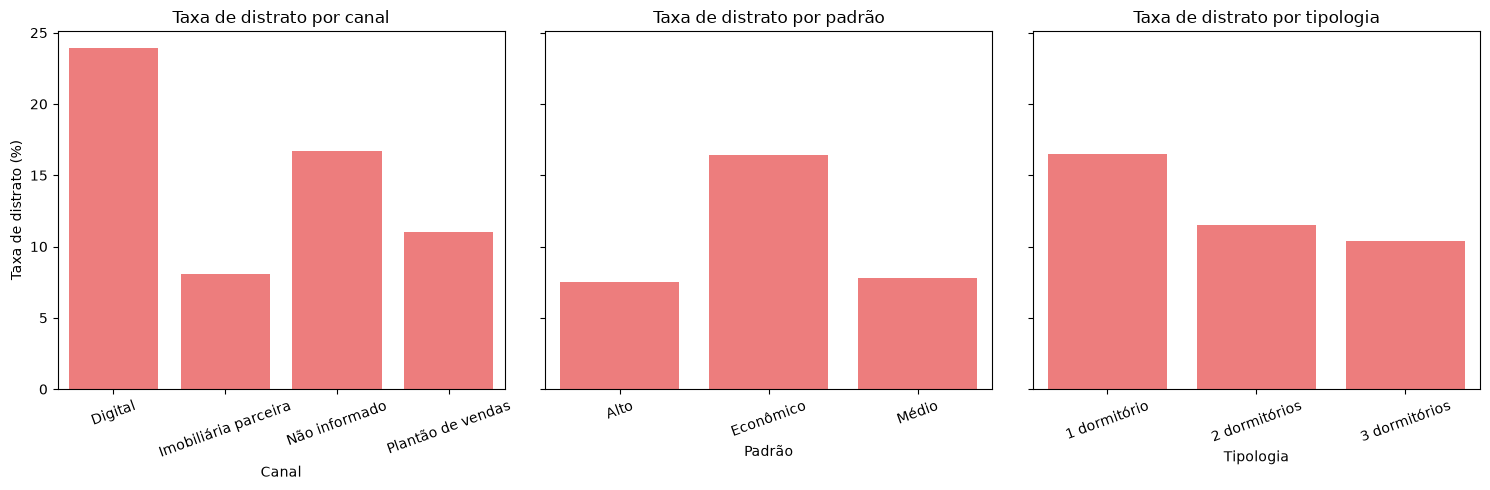

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dimension in zip(axes, ['Canal', 'Padrão', 'Tipologia']):
    data = cancellations[cancellations['dimension'] == dimension]
    sns.barplot(data=data, x='category', y='cancel_rate_pct', color='#FF6B6B', ax=ax)
    ax.set_title(f'Taxa de distrato por {dimension.lower()}')
    ax.set_xlabel(dimension)
    ax.set_ylabel('Taxa de distrato (%)')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Como a maioria das vendas de 1 dormitório está nos empreendimentos econômicos, as dimensões se misturam. Para separar os efeitos, a taxa de distrato é cruzada entre **padrão** e **canal**. As 18 vendas sem canal ficam de fora desse cruzamento.

In [22]:
query = '''
SELECT d.standard,
       s.channel,
       COUNT(*) AS total_sales,
       SUM(CASE WHEN s.status = 'Distratada' THEN 1 ELSE 0 END) AS cancelled_sales,
       ROUND(100.0 * SUM(CASE WHEN s.status = 'Distratada' THEN 1 ELSE 0 END) / COUNT(*), 1) AS cancel_rate_pct
FROM sales s
JOIN units u ON s.unit_id = u.unit_id
JOIN developments d ON u.development_id = d.development_id
WHERE s.channel <> 'Não informado'
GROUP BY d.standard, s.channel
ORDER BY d.standard, s.channel
'''

standard_channel = pd.read_sql(query, conn)
standard_channel

,standard,channel,total_sales,cancelled_sales,cancel_rate_pct
0,Alto,Digital,16,2,12.5
1,Alto,Imobiliária parceira,37,3,8.1
2,Alto,Plantão de vendas,13,0,0.0
3,Econômico,Digital,100,31,31.0
4,Econômico,Imobiliária parceira,208,22,10.6
5,Econômico,Plantão de vendas,120,16,13.3
6,Médio,Digital,60,9,15.0
7,Médio,Imobiliária parceira,113,4,3.5
8,Médio,Plantão de vendas,77,7,9.1


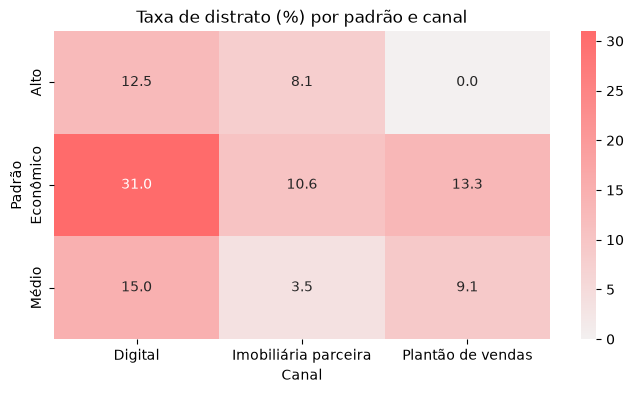

In [23]:
heatmap_data = standard_channel.pivot(index='standard', columns='channel', values='cancel_rate_pct')

plt.figure(figsize=(8, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap=sns.light_palette('#FF6B6B', as_cmap=True))
plt.title('Taxa de distrato (%) por padrão e canal')
plt.xlabel('Canal')
plt.ylabel('Padrão')
plt.show()

**Observações:**

**Fatos**
- A taxa geral de distrato é de **12,7%** (97 de 762 vendas).
- Por canal, o **Digital** tem a maior taxa (**23,9%**), cerca de três vezes a da **Imobiliária parceira** (**8,1%**).
- Por padrão, o **Econômico** distrata **16,4%**, o dobro do Médio (7,8%) e do Alto (7,5%).
- O cruzamento mostra o ponto mais crítico: **Econômico vendido pelo Digital** tem taxa de **31,0%**. Essa combinação responde por 100 das 762 vendas (13%), mas por **31 dos 97 distratos (32%)**.
- O Digital tem a maior taxa em **todos os padrões** (Alto 12,5%, Médio 15,0%, Econômico 31,0%), e a Imobiliária parceira tem a menor no Médio (3,5%).

**Hipóteses**
- No canal Digital, o cliente compra sem visitar o empreendimento e sem acompanhamento de um corretor, e por isso pode desistir com mais facilidade.
- No padrão Econômico, a compra depende mais de financiamento, e a reprovação do crédito pode levar ao distrato.
- O 1 dormitório distrata mais (16,5%) principalmente porque está concentrado nos econômicos, e não pelo tamanho do apartamento em si.
- Os distratos explicam parte do VSO mais baixo do D01 e do D06 visto na seção 6.1.

**Recomendação**
- Rever o processo de venda Digital, principalmente nos econômicos, com análise de crédito antes da assinatura e acompanhamento de um corretor após a venda.
- Acompanhar a taxa de distrato por canal e padrão no painel, com destaque para a combinação Econômico + Digital.

### 6.4 As obras estão dentro do orçamento?

**Estouro de custo:** quanto o custo realizado ficou acima do orçado, em %. A comparação considera apenas os meses de obra já executados até 31/12/2025, e não o orçamento total do empreendimento.

In [24]:
query = '''
SELECT d.development_id,
       d.standard,
       ROUND(SUM(c.budgeted_cost) / 1000000, 1) AS budgeted_mi,
       ROUND(SUM(c.actual_cost) / 1000000, 1) AS actual_mi,
       ROUND(100.0 * (SUM(c.actual_cost) - SUM(c.budgeted_cost)) / SUM(c.budgeted_cost), 1) AS overrun_pct
FROM construction_costs c
JOIN developments d ON c.development_id = d.development_id
GROUP BY d.development_id, d.standard
ORDER BY d.development_id
'''

cost_by_development = pd.read_sql(query, conn)
cost_by_development

,development_id,standard,budgeted_mi,actual_mi,overrun_pct
0,D01,Econômico,23.4,25.2,7.5
1,D02,Alto,23.0,24.8,7.9
2,D03,Econômico,18.2,21.4,17.8
3,D04,Médio,23.5,26.2,11.4
4,D05,Médio,17.1,18.5,8.5
5,D06,Econômico,13.7,16.8,22.3
6,D07,Médio,12.6,13.6,7.5
7,D08,Alto,9.5,10.5,10.2


In [25]:
query = '''
SELECT stage,
       ROUND(SUM(budgeted_cost) / 1000000, 1) AS budgeted_mi,
       ROUND(SUM(actual_cost) / 1000000, 1) AS actual_mi,
       ROUND(100.0 * (SUM(actual_cost) - SUM(budgeted_cost)) / SUM(budgeted_cost), 1) AS overrun_pct
FROM construction_costs
GROUP BY stage
ORDER BY overrun_pct DESC
'''

cost_by_stage = pd.read_sql(query, conn)
cost_by_stage

,stage,budgeted_mi,actual_mi,overrun_pct
0,Estrutura,51.2,60.9,18.9
1,Instalações,23.0,25.2,9.2
2,Acabamento,24.2,25.9,7.0
3,Fundação,18.6,19.9,6.8
4,Alvenaria,23.9,25.1,4.8


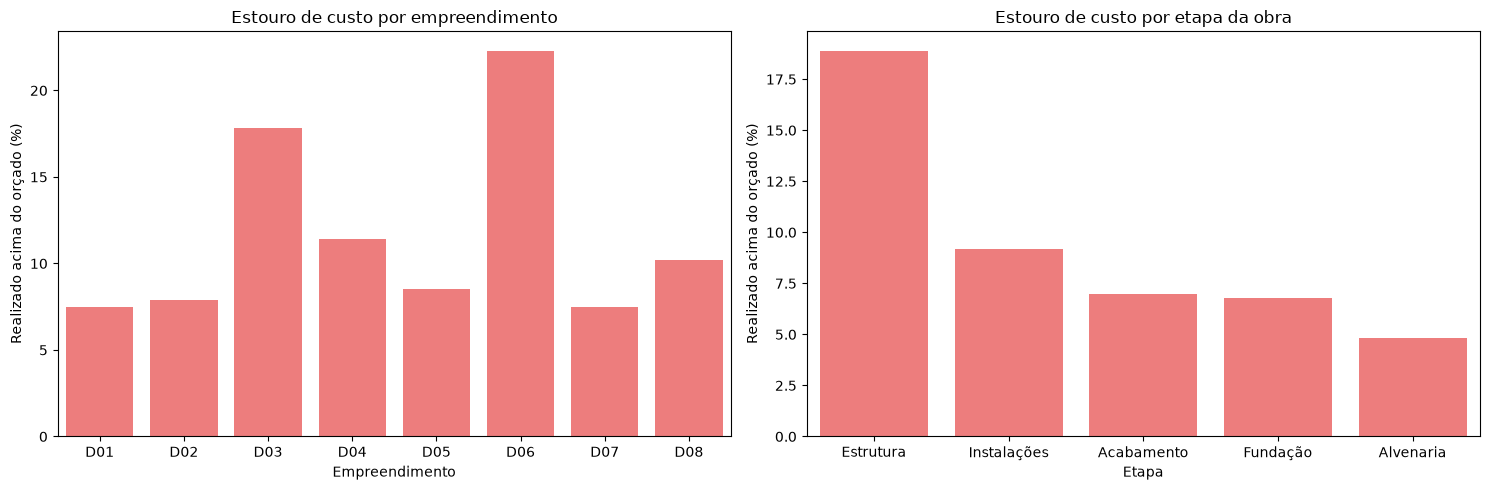

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=cost_by_development, x='development_id', y='overrun_pct', color='#FF6B6B', ax=axes[0])
axes[0].set_title('Estouro de custo por empreendimento')
axes[0].set_xlabel('Empreendimento')
axes[0].set_ylabel('Realizado acima do orçado (%)')

sns.barplot(data=cost_by_stage, x='stage', y='overrun_pct', color='#FF6B6B', ax=axes[1])
axes[1].set_title('Estouro de custo por etapa da obra')
axes[1].set_xlabel('Etapa')
axes[1].set_ylabel('Realizado acima do orçado (%)')

plt.tight_layout()
plt.show()

**Observações:**

**Fatos**
- **Todos os 8 empreendimentos** estão acima do orçado. No total, a empresa gastou **156,9 mi** contra **141,0 mi** orçados para o mesmo período, ou seja, **15,9 mi a mais (+11,3%)**.
- **D06 (+22,3%)** e **D03 (+17,8%)**, ambos do padrão Econômico, têm os maiores estouros, bem acima dos demais. O **D04 (+11,4%)** vem em seguida.
- Por etapa, a **Estrutura** concentra o problema: **+18,9%**, cerca de **9,7 mi** dos 15,9 mi a mais. As outras etapas ficam entre +4,8% (Alvenaria) e +9,2% (Instalações).

**Hipóteses**
- O estouro na Estrutura pode estar ligado à alta de preço de aço e concreto, que pesa em todos os empreendimentos.
- D03 e D06 têm um estouro que vai além da Estrutura e pode indicar problemas de gestão dessas obras específicas (produtividade, retrabalho, fornecedores).
- O D08 (+10,2%) está no começo da obra, justamente na fase de Estrutura, e por isso o percentual dele tende a refletir mais o problema dessa etapa.

**Recomendação**
- Renegociar ou travar preços dos insumos da Estrutura (aço e concreto) nas obras que ainda estão nessa fase.
- Fazer uma auditoria de custos em D06 e D03.
- No painel, acompanhar o orçado x realizado por empreendimento e por etapa, mês a mês.

### 6.5 As obras estão no prazo? Atraso e estouro de custo andam juntos?

- **Desvio de avanço:** avanço físico realizado − previsto no último mês registrado de cada obra, em pontos percentuais (p.p.). Valor negativo significa que a obra está atrás do cronograma.
- **Obra atrasada:** desvio menor que −2 p.p. A tolerância de 2 p.p. evita classificar como atraso pequenas variações de medição.

In [27]:
query = '''
WITH last_month AS (
    SELECT development_id,
           MAX(month) AS month
    FROM construction_progress
    GROUP BY development_id
),
last_progress AS (
    SELECT p.development_id,
           p.planned_progress,
           p.actual_progress
    FROM construction_progress p
    JOIN last_month l ON p.development_id = l.development_id AND p.month = l.month
),
cost AS (
    SELECT development_id,
           100.0 * (SUM(actual_cost) - SUM(budgeted_cost)) / SUM(budgeted_cost) AS overrun_pct
    FROM construction_costs
    GROUP BY development_id
)
SELECT d.development_id,
       d.standard,
       date(d.expected_delivery) AS expected_delivery,
       lp.planned_progress,
       lp.actual_progress,
       ROUND(lp.actual_progress - lp.planned_progress, 1) AS progress_gap_pp,
       ROUND(c.overrun_pct, 1) AS overrun_pct,
       CASE WHEN lp.actual_progress - lp.planned_progress < -2 THEN 'Atrasada' ELSE 'No prazo' END AS schedule_status
FROM developments d
JOIN last_progress lp ON d.development_id = lp.development_id
JOIN cost c ON d.development_id = c.development_id
ORDER BY d.development_id
'''

schedule = pd.read_sql(query, conn)
schedule

,development_id,standard,expected_delivery,planned_progress,actual_progress,progress_gap_pp,overrun_pct,schedule_status
0,D01,Econômico,2025-03-01,100.0,100.0,0.0,7.5,No prazo
1,D02,Alto,2025-08-01,100.0,100.0,0.0,7.9,No prazo
2,D03,Econômico,2026-01-01,99.7,82.1,-17.6,17.8,Atrasada
3,D04,Médio,2025-11-01,100.0,96.8,-3.2,11.4,Atrasada
4,D05,Médio,2026-09-01,82.7,82.2,-0.5,8.5,No prazo
5,D06,Econômico,2026-10-01,75.5,57.7,-17.8,22.3,Atrasada
6,D07,Médio,2026-10-01,70.8,69.5,-1.3,7.5,No prazo
7,D08,Alto,2027-03-01,44.7,44.2,-0.5,10.2,No prazo


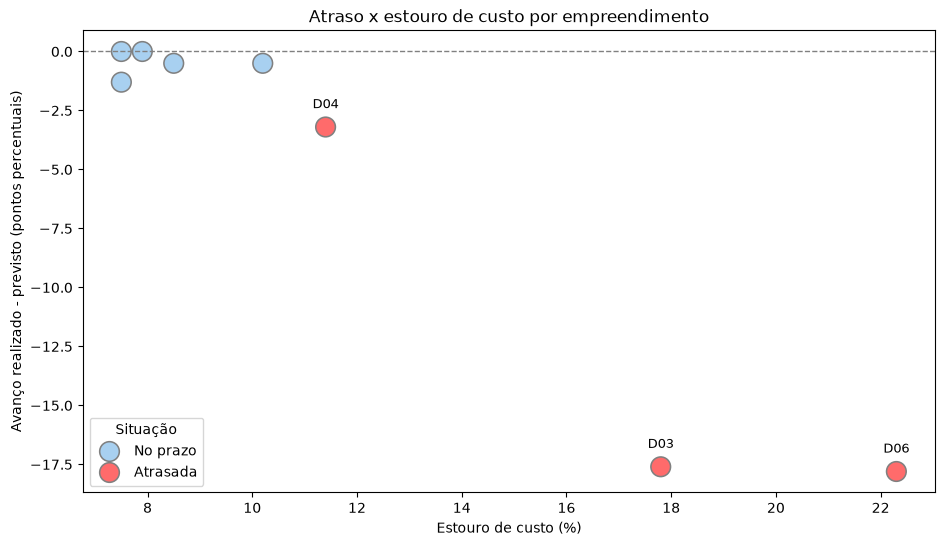

In [28]:
plt.figure(figsize=(11, 6))
sns.scatterplot(data=schedule, x='overrun_pct', y='progress_gap_pp', hue='schedule_status',
                palette={'Atrasada': '#FF6B6B', 'No prazo': '#a8d0f0'}, s=200, edgecolor='gray')

for _, row in schedule[schedule['schedule_status'] == 'Atrasada'].iterrows():
    plt.text(row['overrun_pct'], row['progress_gap_pp'] + 0.8, row['development_id'], ha='center', fontsize=9)

plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Atraso x estouro de custo por empreendimento')
plt.xlabel('Estouro de custo (%)')
plt.ylabel('Avanço realizado - previsto (pontos percentuais)')
plt.legend(title='Situação')
plt.show()

**Observações:**

**Fatos**
- **D01** e **D02** foram entregues no prazo, com 100% de avanço.
- **3 obras estão atrasadas**, e são exatamente as **3 com maior estouro de custo**:
  - **D06 (Econômico):** 57,7% realizado contra 75,5% previsto (**−17,8 p.p.**) e estouro de **22,3%**.
  - **D03 (Econômico):** 82,1% realizado contra 99,7% previsto (**−17,6 p.p.**) e estouro de **17,8%**. A entrega está prevista para janeiro de 2026.
  - **D04 (Médio):** a entrega estava prevista para novembro de 2025, mas a obra está com 96,8% em dezembro (**−3,2 p.p.**), e o estouro é de **11,4%**.
- As 5 obras no prazo têm estouro entre **7,5% e 10,2%**.

**Hipóteses**
- Atraso e estouro andam juntos: obras mais lentas ficam mais tempo com equipe e equipamentos mobilizados, o que encarece a obra. O contrário também pode acontecer, quando a falta de dinheiro ou de material atrasa o cronograma. Os dados mostram a relação, mas não dizem qual vem primeiro.
- Com 82,1% de avanço a um mês da data prevista, o **D03 não deve ser entregue no prazo**, o que pode gerar multas contratuais e insatisfação dos compradores.

**Recomendação**
- Priorizar D03 e D06 com um plano de recuperação de cronograma e custo.
- Comunicar com antecedência os compradores do D03 e do D04 sobre o novo prazo de entrega.
- No painel, acompanhar mês a mês a curva de avanço previsto x realizado de cada obra.

### 6.6 Quais empreendimentos precisam de atenção da diretoria?

Cada empreendimento recebe um **alerta** para cada indicador fora do esperado:

| Indicador | Alerta quando | Referência |
|---|---|---|
| Taxa de distrato | Acima de 12,7% | Taxa geral da empresa (seção 6.3) |
| Estouro de custo | Acima de 11,3% | Estouro geral da empresa (seção 6.4) |
| Desvio de avanço | Abaixo de −2 p.p. | Critério de atraso (seção 6.5) |

**Prioridade:** 2 ou 3 alertas = **Alta**, 1 alerta = **Média**, nenhum = **Acompanhar**. O VSO aparece na tabela como contexto, mas não gera alerta, porque depende do tempo de venda de cada empreendimento (seção 6.1).

In [29]:
query = '''
WITH sales_summary AS (
    SELECT u.development_id,
           SUM(CASE WHEN s.status = 'Ativa' THEN 1 ELSE 0 END) AS units_sold,
           100.0 * SUM(CASE WHEN s.status = 'Distratada' THEN 1 ELSE 0 END) / COUNT(*) AS cancel_rate_pct
    FROM sales s
    JOIN units u ON s.unit_id = u.unit_id
    GROUP BY u.development_id
),
cost AS (
    SELECT development_id,
           100.0 * (SUM(actual_cost) - SUM(budgeted_cost)) / SUM(budgeted_cost) AS overrun_pct
    FROM construction_costs
    GROUP BY development_id
),
last_month AS (
    SELECT development_id,
           MAX(month) AS month
    FROM construction_progress
    GROUP BY development_id
),
last_progress AS (
    SELECT p.development_id,
           p.actual_progress - p.planned_progress AS progress_gap_pp
    FROM construction_progress p
    JOIN last_month l ON p.development_id = l.development_id AND p.month = l.month
),
scorecard AS (
    SELECT d.development_id,
           d.development_name,
           d.standard,
           ROUND(100.0 * ss.units_sold / d.total_units, 1) AS vso_pct,
           ROUND(ss.cancel_rate_pct, 1) AS cancel_rate_pct,
           ROUND(c.overrun_pct, 1) AS overrun_pct,
           ROUND(lp.progress_gap_pp, 1) AS progress_gap_pp,
           CASE WHEN ss.cancel_rate_pct > 12.7 THEN 1 ELSE 0 END AS cancel_alert,
           CASE WHEN c.overrun_pct > 11.3 THEN 1 ELSE 0 END AS cost_alert,
           CASE WHEN lp.progress_gap_pp < -2 THEN 1 ELSE 0 END AS schedule_alert
    FROM developments d
    JOIN sales_summary ss ON d.development_id = ss.development_id
    JOIN cost c ON d.development_id = c.development_id
    JOIN last_progress lp ON d.development_id = lp.development_id
)
SELECT *,
       cancel_alert + cost_alert + schedule_alert AS alerts,
       CASE WHEN cancel_alert + cost_alert + schedule_alert >= 2 THEN 'Alta'
            WHEN cancel_alert + cost_alert + schedule_alert = 1 THEN 'Média'
            ELSE 'Acompanhar' END AS priority
FROM scorecard
ORDER BY alerts DESC, overrun_pct DESC
'''

scorecard = pd.read_sql(query, conn)
scorecard

,development_id,development_name,standard,vso_pct,cancel_rate_pct,overrun_pct,progress_gap_pp,cancel_alert,cost_alert,schedule_alert,alerts,priority
0,D06,Edifício Horizonte,Econômico,72.7,15.8,22.3,-17.8,1,1,1,3,Alta
1,D03,Residencial Parque Verde,Econômico,82.3,15.3,17.8,-17.6,1,1,1,3,Alta
2,D04,Edifício Solar do Vale,Médio,90.7,5.4,11.4,-3.2,0,1,1,2,Alta
3,D01,Residencial Jardim das Flores,Econômico,77.8,17.6,7.5,0.0,1,0,0,1,Média
4,D08,Edifício Alto da Serra,Alto,60.5,7.1,10.2,-0.5,0,0,0,0,Acompanhar
5,D05,Residencial Bela Vista,Médio,86.3,9.9,8.5,-0.5,0,0,0,0,Acompanhar
6,D02,Edifício Mirante,Alto,83.7,7.7,7.9,0.0,0,0,0,0,Acompanhar
7,D07,Residencial Recanto,Médio,73.9,8.5,7.5,-1.3,0,0,0,0,Acompanhar


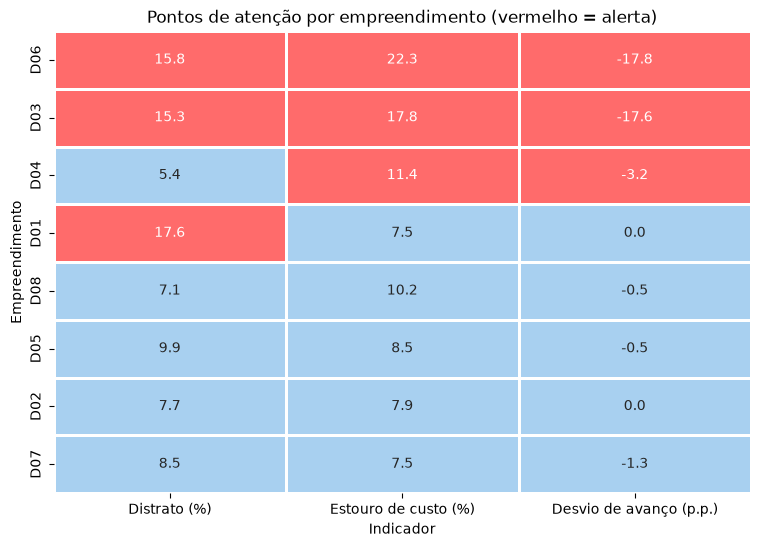

In [30]:
indicators = scorecard.set_index('development_id')[['cancel_rate_pct', 'overrun_pct', 'progress_gap_pp']]
alerts = scorecard.set_index('development_id')[['cancel_alert', 'cost_alert', 'schedule_alert']]

plt.figure(figsize=(9, 6))
sns.heatmap(alerts, annot=indicators, fmt='.1f', cmap=['#a8d0f0', '#FF6B6B'], cbar=False,
            linewidths=2, linecolor='white',
            xticklabels=['Distrato (%)', 'Estouro de custo (%)', 'Desvio de avanço (p.p.)'])
plt.title('Pontos de atenção por empreendimento (vermelho = alerta)')
plt.xlabel('Indicador')
plt.ylabel('Empreendimento')
plt.show()

**Observações:**

**Fatos**
- **Prioridade Alta (3 empreendimentos):**
  - **D06 e D03 (Econômico)** acendem os **3 alertas**: distrato acima da média (15,8% e 15,3%), os maiores estouros de custo (22,3% e 17,8%) e atraso de quase 18 p.p.
  - **D04 (Médio)** tem 2 alertas: passou da data de entrega sem concluir a obra (−3,2 p.p.) e tem estouro de 11,4%, logo acima da média da empresa. Já no comercial, é o melhor empreendimento: maior VSO (90,7%) e menor distrato (5,4%).
- **Prioridade Média:** o **D01 (Econômico)** já foi entregue e está dentro do custo esperado, mas tem a **maior taxa de distrato** da empresa (17,6%) e ainda 40 unidades sem venda ativa.
- **Acompanhar:** D02, D05, D07 e D08 não têm nenhum alerta.

**Hipóteses**
- Os problemas se concentram nos **empreendimentos econômicos**, que reúnem o maior distrato e as obras com mais dificuldade.
- O alerta de custo do D04 está no limite (11,4% contra 11,3% de referência). O ponto mais urgente dele é o atraso na entrega.

**Recomendação**
- Montar um comitê de acompanhamento para **D06 e D03**, com revisão de cronograma, auditoria de custos e ações para reduzir distratos.
- Definir o novo prazo de entrega do **D04** e comunicar os compradores.
- Criar uma ação comercial para o estoque do **D01**, que já está pronto para morar e pode ser um argumento de venda.
- Levar esses três indicadores e o critério de alerta para a página **Visão Geral** do painel.

## 7. Modelagem dos dados para o Power BI

As bases limpas são exportadas para o Power BI no formato de **esquema estrela**: tabelas de **dimensão** (cadastros, com uma linha por item) se ligam às tabelas **fato** (acontecimentos, com muitas linhas).

| Arquivo | Tabela no Power BI | Tipo | Uma linha por | Chave | Liga com |
|---|---|---|---|---|---|
| `developments_clean.csv` | `developments` | Dimensão | Empreendimento | `development_id` | `units`, `construction_costs`, `construction_progress` |
| `units_clean.csv` | `units` | Dimensão | Unidade | `unit_id` | `developments` e `sales` |
| `sales_clean.csv` | `sales` | Fato | Venda | `sale_id` | `units` (por `unit_id`) |
| `construction_costs_clean.csv` | `construction_costs` | Fato | Empreendimento + mês + etapa | - | `developments` (por `development_id`) |
| `construction_progress_clean.csv` | `construction_progress` | Fato | Empreendimento + mês | - | `developments` (por `development_id`) |
| - | `calendar` | Dimensão | Dia | `Date` | Criada no Power BI com DAX |

```
                 developments
               /      |       \
          units   construction   construction
            |        _costs        _progress
          sales
```

As vendas chegam aos empreendimentos passando pelas unidades. Assim, um filtro de empreendimento ou de tipologia alcança as vendas, e as unidades ainda não vendidas continuam disponíveis para o cálculo do VGV total e do VSO.

### 7.1 Integridade das chaves

Antes de exportar, é preciso garantir que as chaves das dimensões são únicas e que todo registro dos fatos encontra o seu par na dimensão. Caso contrário, os relacionamentos no Power BI falham ou deixam linhas "soltas".

In [31]:
checks = {
    'development_id único em developments': developments['development_id'].is_unique,
    'unit_id único em units': units['unit_id'].is_unique,
    'todas as unidades têm empreendimento': units['development_id'].isin(developments['development_id']).all(),
    'todas as vendas têm unidade': sales['unit_id'].isin(units['unit_id']).all(),
    'todos os custos têm empreendimento': construction_costs['development_id'].isin(developments['development_id']).all(),
    'todo avanço tem empreendimento': construction_progress['development_id'].isin(developments['development_id']).all(),
}

for check, result in checks.items():
    print(f'{check}: {result}')

development_id único em developments: True
unit_id único em units: True
todas as unidades têm empreendimento: True
todas as vendas têm unidade: True
todos os custos têm empreendimento: True
todo avanço tem empreendimento: True


### 7.2 Exportação das bases limpas

In [32]:
for name, df in tables.items():
    df.to_csv(f'{name}_clean.csv', index=False)
    print(f'{name}_clean.csv: {len(df)} linhas')

developments_clean.csv: 8 linhas
units_clean.csv: 841 linhas
sales_clean.csv: 762 linhas
construction_costs_clean.csv: 375 linhas
construction_progress_clean.csv: 207 linhas


## 8. Conclusões e Recomendações

### 8.1 Respostas às perguntas de negócio

**1. Como estão as vendas (VGV vendido e VSO)?**
A empresa vendeu **665 das 841 unidades (VSO de 79,1%)**, somando **R$ 285,7 mi** de VGV vendido de um total de R$ 379,5 mi. As vendas cresceram até o pico de **2024 (313 vendas)** e caíram em 2025, ano sem lançamentos. O **Edifício Solar do Vale (D04)** tem o maior VSO (90,7%), e o **Edifício Alto da Serra (D08)** o menor (60,5%), compatível com ser o lançamento mais recente.

**2. Qual é a taxa de distrato e onde se concentra?**
A taxa geral é de **12,7%**. Ela se concentra no canal **Digital (23,9%)** e no padrão **Econômico (16,4%)**. A combinação **Econômico + Digital** tem taxa de **31,0%**: representa 13% das vendas, mas **32% dos distratos**.

**3. As obras estão dentro do orçamento?**
Não. **Todas as 8 obras** estão acima do orçado, somando **R$ 15,9 mi a mais (+11,3%)**. A etapa de **Estrutura (+18,9%)** responde por cerca de R$ 9,7 mi desse valor. **Edifício Horizonte (D06, +22,3%)** e **Residencial Parque Verde (D03, +17,8%)** têm os maiores estouros.

**4. As obras estão no prazo? Atraso e estouro andam juntos?**
**3 obras estão atrasadas (D06, D03 e D04)** e são exatamente as 3 com maior estouro de custo. A relação existe nos dados, mas eles não mostram qual problema causa o outro.

**5. Quais empreendimentos precisam de atenção?**
- **Prioridade alta:** Edifício Horizonte (D06) e Residencial Parque Verde (D03), com os 3 alertas, e Edifício Solar do Vale (D04), atrasado e acima do custo.
- **Prioridade média:** Residencial Jardim das Flores (D01), com a maior taxa de distrato da empresa (17,6%).

### 8.2 Principais descobertas

- O problema de lucro da Vértice Urbano não está na venda, e sim no que acontece **depois** dela: distratos no comercial e estouro de custo e prazo nas obras.
- Os problemas se concentram nos **empreendimentos econômicos**, que reúnem o maior distrato e as obras com mais dificuldade.
- A venda **digital** traz volume, mas com uma taxa de desistência três vezes maior que a das imobiliárias parceiras.
- A alta de custo da **Estrutura** atinge todas as obras e é o principal ponto de controle de custo da empresa.

### 8.3 Ações recomendadas

| Prioridade | Ação | Onde | Indicador para acompanhar |
|---|---|---|---|
| Alta | Plano de recuperação de cronograma e auditoria de custos | D06 e D03 | Desvio de avanço e estouro de custo |
| Alta | Definir o novo prazo de entrega e comunicar os compradores | D04 e D03 | Desvio de avanço |
| Alta | Análise de crédito antes da assinatura e acompanhamento de um corretor após a venda | Vendas digitais, principalmente no Econômico | Taxa de distrato por canal |
| Média | Renegociar ou travar o preço de aço e concreto | Obras ainda na fase de Estrutura, como o D08 | Estouro de custo da Estrutura |
| Média | Ação comercial para o estoque pronto para morar | D01 | VSO e taxa de distrato |
| Média | Planejar os próximos lançamentos para manter o ritmo de vendas | Empresa | Vendas por ano |

### 8.4 Limitações

- Os dados são **fictícios**, gerados com relações de negócio embutidas para fins de estudo.
- A taxa de distrato das vendas mais recentes ainda está **em maturação**, porque os distratos acontecem meses depois da venda.
- Algumas decisões de limpeza afetam levemente os números: 6 vendas sem valor foram preenchidas com o preço de tabela (estimativa), 5 distratos ficaram sem data e 5 meses de custo foram removidos por não ter o valor realizado.
- Os limites de alerta usam a **média da empresa** como referência, e não metas oficiais da diretoria.
- A análise mostra **associações** (por exemplo, entre atraso e estouro de custo), não causas.
- A parte financeira (recebimentos, inadimplência e margem) ficou fora do escopo.

### 8.5 Próximos passos

- Incluir a frente **financeira**: recebimentos, inadimplência e margem por empreendimento.
- Definir com a diretoria **metas oficiais** para distrato, custo e prazo, e usá-las como limites de alerta no painel.
- Acompanhar o distrato **por safra de vendas**, comparando cada ano só depois do mesmo tempo de maturação.
- Publicar o painel no **Power BI Service** com atualização mensal automática.

## 9. Deploy: como reproduzir o projeto

### 9.1 Pré-requisitos

- **Python 3.10+** e **Git**
- **Jupyter Notebook** instalado no ambiente global
- **Power BI Desktop** (gratuito, somente Windows)

### 9.2 Passo a passo

**1. Clonar o repositório e criar o ambiente virtual** (Prompt de Comando do Windows):

```bash
git clone https://github.com/ricardo-paganini/construction-powerbi-dashboard.git
cd construction-powerbi-dashboard
python -m venv venv
venv\Scripts\activate
pip install -r requirements.txt
python -m ipykernel install --user --name=construction-powerbi-venv --display-name="Python (construction-powerbi)"
```

No Linux ou Mac, a ativação do ambiente é `source venv/bin/activate`.

**2. (Opcional) Gerar as bases de novo**

As bases originais já estão no repositório. Para gerá-las do zero (o resultado é idêntico, graças à semente fixa):

```bash
python generate_data.py
```

**3. Rodar o notebook**

```bash
jupyter notebook
```

Abra o `construction_analysis.ipynb`, selecione o kernel **Python (construction-powerbi)** e execute **Kernel > Restart & Run All**. Ao final, os arquivos `*_clean.csv` são gerados na raiz do projeto.

**4. Abrir o painel no Power BI**

1. Abra o `construction_dashboard.pbix` no Power BI Desktop.
2. Vá em **Página Inicial > Transformar dados** e clique no parâmetro **`project_folder`**.
3. Troque o valor pelo caminho da pasta do projeto no seu computador, **terminando com `\`** (ex.: `C:\Users\seu_usuario\construction-powerbi-dashboard\`).
4. Clique em **Fechar e Aplicar**. O painel é atualizado com os dados limpos.

Para consultar o painel sem o Power BI, use o arquivo `construction_dashboard.pdf`.

### 9.3 Estrutura do projeto

Todos os arquivos ficam na raiz do projeto:

```
construction-powerbi-dashboard/
├── generate_data.py                  # gera as bases fictícias (semente fixa)
├── developments.csv                  # bases originais, com os problemas de qualidade
├── units.csv
├── sales.csv
├── construction_costs.csv
├── construction_progress.csv
├── construction_analysis.ipynb       # este notebook (CRISP-DM)
├── developments_clean.csv            # bases limpas, lidas pelo Power BI
├── units_clean.csv
├── sales_clean.csv
├── construction_costs_clean.csv
├── construction_progress_clean.csv
├── construction_dashboard.pbix       # painel no Power BI
├── construction_dashboard.pdf        # painel exportado em PDF
├── theme.json                        # tema de cores do painel
├── dashboard_overview.png            # imagens das páginas do painel
├── dashboard_commercial.png
├── dashboard_construction.png
├── requirements.txt                  # bibliotecas e versões
├── .gitignore
└── README.md
```